# 02 — Spectral Indices & Differential Analysis

Derives NDVI, EVI and NBR from the summer median composites (`src/landsat_composites.py`) using `src/indices.py`, then:

1. Renders the differential maps **ΔNDVI** and **ΔNBR** (T3 − T1, 2022–2025 minus 1985–1991) for Gallura (Limbara & Inland), Lucanian Apennines (Val d'Agri), Apuan Alps (Mountain Core), and Fiemme Valley & Paneveggio.
2. Builds `results/summary_stats.csv` with the columns Region, Total Area (km²), Expanded Forest (km²), Mean ΔNDVI, Mean ΔNBR.

**Method notes**
- Δ = recent − baseline, so positive values mean greener or denser canopy (for NBR: recovery). This is the opposite sign of classic burn-severity dNBR (pre − post).
- A pixel is *forest* when its summer NDVI ≥ `FOREST_NDVI_THRESHOLD` (default 0.6). *Expanded forest* = non-forest in T1 and forest in T3.
- Water pixels are masked before calculating AOI means. *Total Area* is the full bounding-box area defined in `config/areas.json`.
- T1 is Landsat 5 TM and T3 is Landsat 8/9 OLI. No cross-sensor harmonization is applied, so small systematic sensor offsets are part of the Δ.

## 1. Setup

The shared GEE project ID is loaded from `config/project_id.json`. On first use, `ee.Authenticate()` opens the browser sign-in.

In [2]:
import json
import os
import sys
from pathlib import Path

import ee
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.indices import add_all_indices
from src.landsat_composites import (
    AREA_KEYS,
    CONFIG_DIR,
    get_median_composite,
    load_areas,
    load_time_periods,
)

In [3]:
import importlib
import src.landsat_composites as landsat_composites

importlib.reload(landsat_composites)
PROJECT_ID = landsat_composites.load_project_id()

try:
    ee.Initialize(project=PROJECT_ID)
except ee.EEException:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)

print("Google Earth Engine initialized successfully.")

Google Earth Engine initialized successfully.


## 2. Parameters

In [4]:
BASELINE_PERIOD = "T1"
RECENT_PERIOD = "T3"
FOREST_NDVI_THRESHOLD = 0.6
MASK_WATER = True

STATS_SCALE = 30
MAP_LONG_SIDE_PX = 1000
NODATA = -9999

DELTA_BANDS = {
    "dNDVI": {"label": "ΔNDVI", "limit": 0.4},
    "dNBR": {"label": "ΔNBR", "limit": 0.5},
}

RESULTS_DIR = PROJECT_ROOT / "results"
MAPS_DIR = RESULTS_DIR / "maps"
MAPS_DIR.mkdir(parents=True, exist_ok=True)

## 3. Regions and time periods

In [5]:
areas = load_areas()
config = load_time_periods()
area_info = json.loads((CONFIG_DIR / "areas.json").read_text(encoding="utf-8"))

baseline = config["periods"][BASELINE_PERIOD]
recent = config["periods"][RECENT_PERIOD]
delta_suffix = f"{RECENT_PERIOD}_minus_{BASELINE_PERIOD}"
delta_years = (
    f"{recent['start_year']}–{recent['end_year']} minus "
    f"{baseline['start_year']}–{baseline['end_year']}"
)

print(f"Δ = {RECENT_PERIOD} − {BASELINE_PERIOD} ({delta_years})")
for key in AREA_KEYS:
    print(f"  {key:12s} {area_info[key]['name']:20s} bbox={area_info[key]['bbox']}")

Δ = T3 − T1 (2022–2025 minus 1985–1991)
  gallura      Gallura (Limbara & Inland) bbox=[9.05, 40.78, 9.65, 41.08]
  basilicata   Lucanian Apennines (Val d'Agri) bbox=[15.65, 40.25, 16.25, 40.65]
  alpi_apuane  Apuan Alps (Mountain Core) bbox=[10.12, 44.02, 10.45, 44.28]
  trento       Fiemme Valley & Paneveggio (Vaia Storm Area) bbox=[11.45, 46.2, 11.85, 46.38]


## 4. Index composites and Δ images

`add_all_indices` needs the sensor band mapping: Landsat 8/9 periods use `L8_L9`, Landsat 5/7 periods use `L5_L7`. Each Δ image holds `dNDVI`, `dNBR` and a binary `expanded_forest` band.

In [6]:
OLI_SENSORS = {"LC08", "LC09"}


def sensor_type_for(period):
    sensors = {collection_id.split("/")[1] for collection_id in period["collection_ids"]}
    if sensors <= OLI_SENSORS:
        return "L8_L9"
    if sensors.isdisjoint(OLI_SENSORS):
        return "L5_L7"
    raise ValueError(f"Period {period['name']!r} mixes OLI and TM/ETM+ collections.")


def index_composite(aoi, period):
    composite = get_median_composite(aoi, period, config)
    return add_all_indices(composite, sensor_type_for(period)).select(["NDVI", "EVI", "NBR"])


def land_mask():
    worldcover = ee.ImageCollection("ESA/WorldCover/v200").first()
    return worldcover.neq(80)


def delta_image(aoi):
    before = index_composite(aoi, baseline)
    after = index_composite(aoi, recent)

    delta = (
        after.select(["NDVI", "NBR"])
        .subtract(before.select(["NDVI", "NBR"]))
        .rename(list(DELTA_BANDS))
        .toFloat()
    )
    forest_before = before.select("NDVI").gte(FOREST_NDVI_THRESHOLD)
    forest_after = after.select("NDVI").gte(FOREST_NDVI_THRESHOLD)
    expanded = forest_after.And(forest_before.Not()).rename("expanded_forest")

    image = delta.addBands(expanded)
    return image.updateMask(land_mask()) if MASK_WATER else image


deltas = {key: delta_image(areas[key]) for key in AREA_KEYS}

## 5. Differential maps (PNG)

Pixels are fetched with `ee.data.computePixels` on a lat/lon grid (longest side = `MAP_LONG_SIDE_PX`), plotted with matplotlib and saved to `results/maps/`. Brown = decrease, green = increase, grey = masked (water or no clear observation).

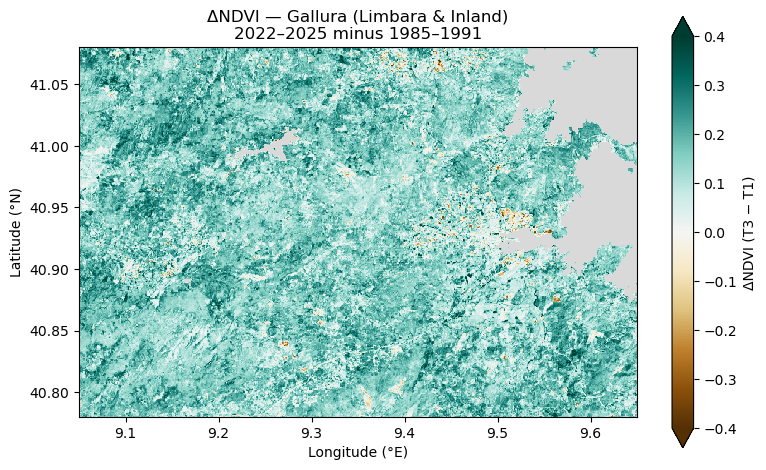

Saved results/maps/gallura_dNDVI_T3_minus_T1.png


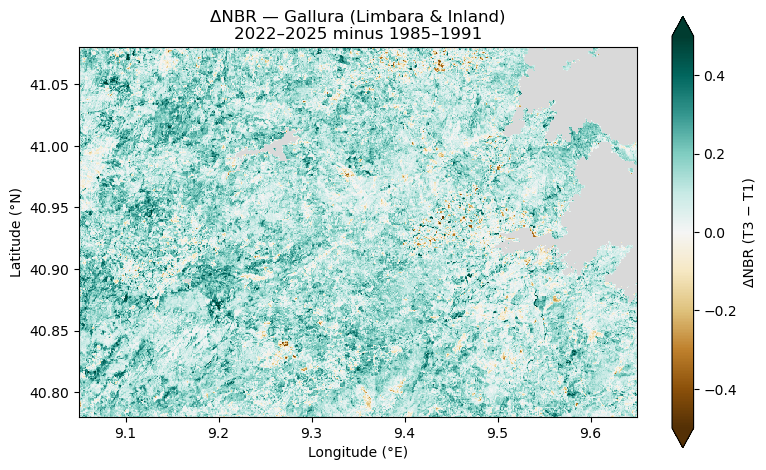

Saved results/maps/gallura_dNBR_T3_minus_T1.png


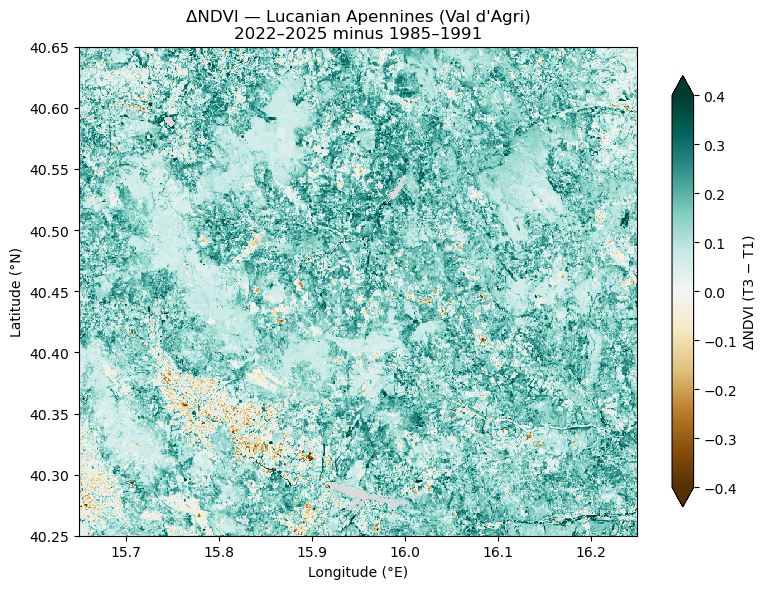

Saved results/maps/basilicata_dNDVI_T3_minus_T1.png


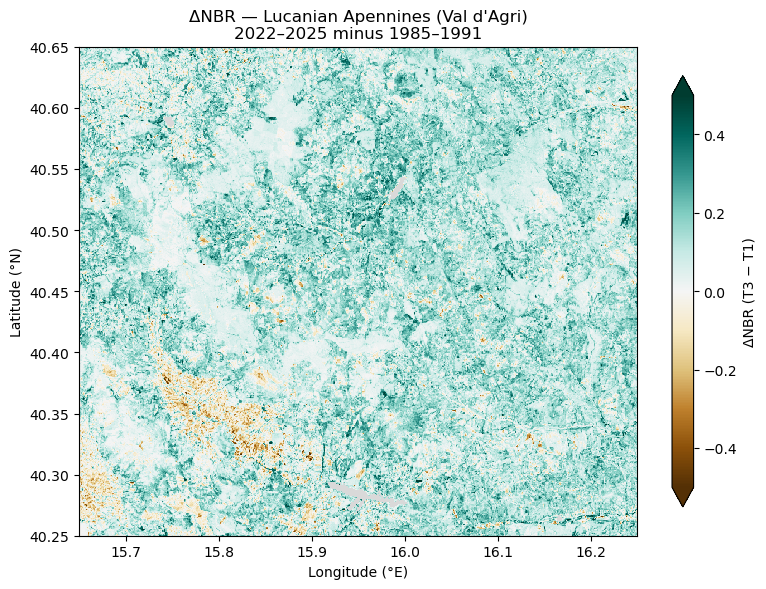

Saved results/maps/basilicata_dNBR_T3_minus_T1.png


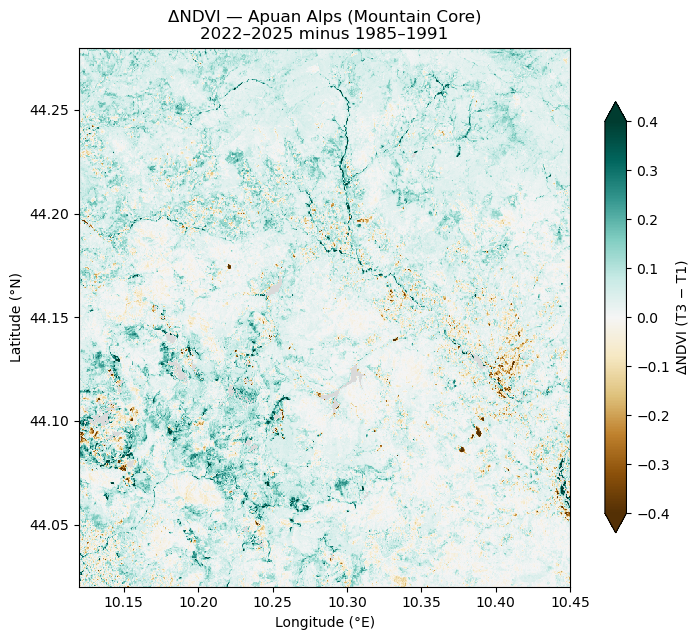

Saved results/maps/alpi_apuane_dNDVI_T3_minus_T1.png


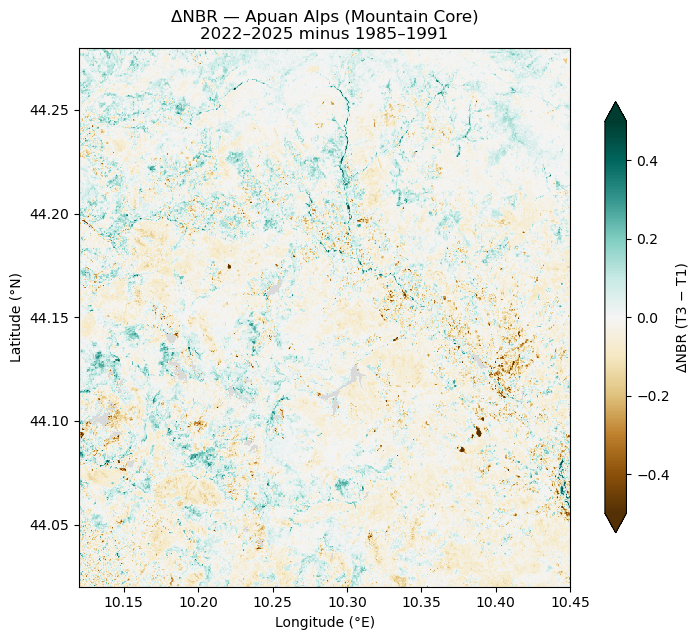

Saved results/maps/alpi_apuane_dNBR_T3_minus_T1.png


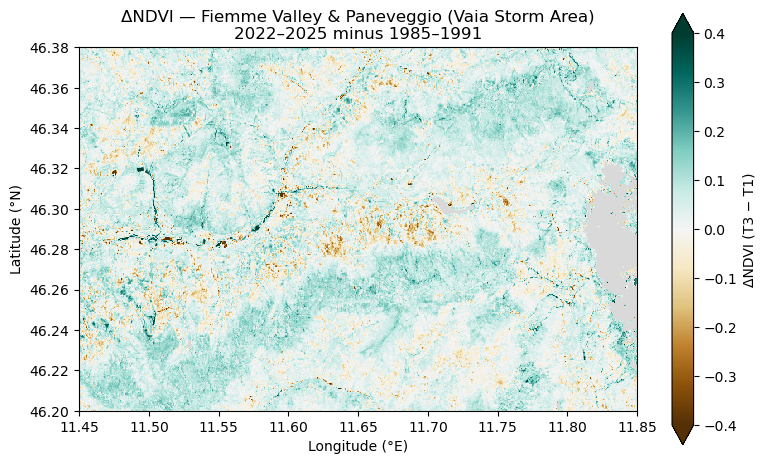

Saved results/maps/trento_dNDVI_T3_minus_T1.png


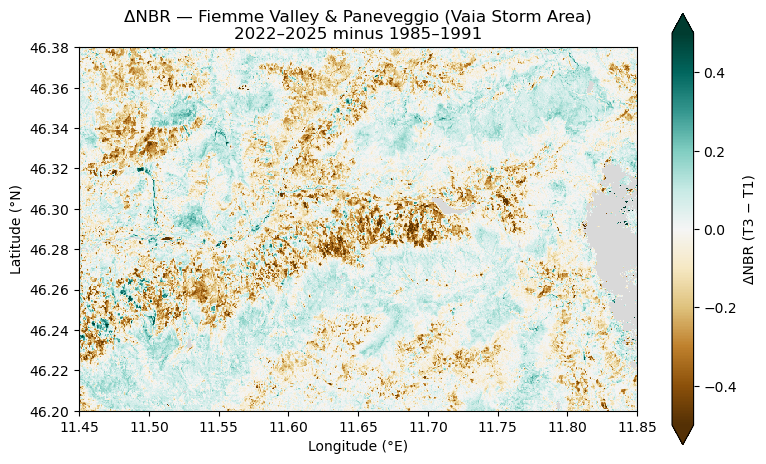

Saved results/maps/trento_dNBR_T3_minus_T1.png


In [7]:
def fetch_bands(image, bbox, bands):
    xmin, ymin, xmax, ymax = bbox
    pixel_deg = max(xmax - xmin, ymax - ymin) / MAP_LONG_SIDE_PX
    request = {
        "expression": image.select(bands).unmask(NODATA),
        "fileFormat": "NUMPY_NDARRAY",
        "grid": {
            "dimensions": {
                "width": int(round((xmax - xmin) / pixel_deg)),
                "height": int(round((ymax - ymin) / pixel_deg)),
            },
            "affineTransform": {
                "scaleX": pixel_deg,
                "shearX": 0,
                "translateX": xmin,
                "shearY": 0,
                "scaleY": -pixel_deg,
                "translateY": ymax,
            },
            "crsCode": "EPSG:4326",
        },
    }
    pixels = ee.data.computePixels(request)
    return {band: np.where(pixels[band] == NODATA, np.nan, pixels[band]) for band in bands}


def save_delta_map(key, band, array):
    xmin, ymin, xmax, ymax = area_info[key]["bbox"]
    spec = DELTA_BANDS[band]
    cmap = plt.get_cmap("BrBG").copy()
    cmap.set_bad("#d9d9d9")

    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(
        np.ma.masked_invalid(array),
        cmap=cmap,
        vmin=-spec["limit"],
        vmax=spec["limit"],
        extent=(xmin, xmax, ymin, ymax),
        interpolation="nearest",
    )
    ax.set_aspect(1 / np.cos(np.deg2rad((ymin + ymax) / 2)))
    ax.set_title(f"{spec['label']} — {area_info[key]['name']}\n{delta_years}")
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    fig.colorbar(
        im,
        ax=ax,
        shrink=0.8,
        extend="both",
        label=f"{spec['label']} ({RECENT_PERIOD} − {BASELINE_PERIOD})",
    )

    path = MAPS_DIR / f"{key}_{band}_{delta_suffix}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    return path


for key in AREA_KEYS:
    arrays = fetch_bands(deltas[key], area_info[key]["bbox"], list(DELTA_BANDS))
    for band, array in arrays.items():
        print("Saved", save_delta_map(key, band, array).relative_to(PROJECT_ROOT))

## 6. Summary statistics

Means and expanded-forest area are computed at `STATS_SCALE` m over the (land-masked) pixels of each region. If a region times out, raise `STATS_SCALE` (e.g. 60) or move the reduction to `ee.batch.Export.table`.

In [8]:
def region_stats(key):
    aoi = areas[key]
    image = deltas[key]
    reduce_kwargs = {"geometry": aoi, "scale": STATS_SCALE, "maxPixels": 1e13, "tileScale": 4}

    means = image.select(list(DELTA_BANDS)).reduceRegion(reducer=ee.Reducer.mean(), **reduce_kwargs)
    expanded_m2 = (
        image.select("expanded_forest")
        .multiply(ee.Image.pixelArea())
        .reduceRegion(reducer=ee.Reducer.sum(), **reduce_kwargs)
    )
    stats = ee.Dictionary({
        "total_m2": aoi.area(maxError=1),
        "expanded_m2": expanded_m2.get("expanded_forest"),
        "dNDVI": means.get("dNDVI"),
        "dNBR": means.get("dNBR"),
    }).getInfo()

    return {
        "Region": area_info[key]["name"],
        "Total Area (km²)": stats["total_m2"] / 1e6,
        "Expanded Forest (km²)": stats["expanded_m2"] / 1e6,
        "Mean ΔNDVI": stats["dNDVI"],
        "Mean ΔNBR": stats["dNBR"],
    }


rows = []
for key in AREA_KEYS:
    print(f"Computing statistics for {area_info[key]['name']}...")
    rows.append(region_stats(key))

summary = pd.DataFrame(rows).round({
    "Total Area (km²)": 2,
    "Expanded Forest (km²)": 2,
    "Mean ΔNDVI": 4,
    "Mean ΔNBR": 4,
})

summary_path = RESULTS_DIR / "summary_stats.csv"
summary.to_csv(summary_path, index=False)
print("Saved", summary_path.relative_to(PROJECT_ROOT))
summary

Computing statistics for Gallura (Limbara & Inland)...
Computing statistics for Lucanian Apennines (Val d'Agri)...
Computing statistics for Apuan Alps (Mountain Core)...
Computing statistics for Fiemme Valley & Paneveggio (Vaia Storm Area)...
Saved results/summary_stats.csv


,Region,Total Area (km²),Expanded Forest (km²),Mean ΔNDVI,Mean ΔNBR
0,Gallura (Limbara & Inland),1681.45,530.72,0.1489,0.1201
1,Lucanian Apennines (Val d'Agri),2258.14,547.78,0.1251,0.1028
2,Apuan Alps (Mountain Core),761.19,23.44,0.0386,-0.0046
3,Fiemme Valley & Paneveggio (Vaia Storm Area),615.16,41.63,0.0391,-0.0180


## 7. NDVI thumbnails

Save T1, T2, and T3 NDVI PNGs for each AOI. All images use the same 0.0–0.8 range and palette, with the same WorldCover water mask.

Using existing results/ndvi_thumbnails/gallura_T1_NDVI.png
Using existing results/ndvi_thumbnails/gallura_T2_NDVI.png
Using existing results/ndvi_thumbnails/gallura_T3_NDVI.png
Using existing results/ndvi_thumbnails/basilicata_T1_NDVI.png
Using existing results/ndvi_thumbnails/basilicata_T2_NDVI.png
Using existing results/ndvi_thumbnails/basilicata_T3_NDVI.png
Using existing results/ndvi_thumbnails/alpi_apuane_T1_NDVI.png
Using existing results/ndvi_thumbnails/alpi_apuane_T2_NDVI.png
Using existing results/ndvi_thumbnails/alpi_apuane_T3_NDVI.png
Using existing results/ndvi_thumbnails/trento_T1_NDVI.png
Using existing results/ndvi_thumbnails/trento_T2_NDVI.png
Using existing results/ndvi_thumbnails/trento_T3_NDVI.png


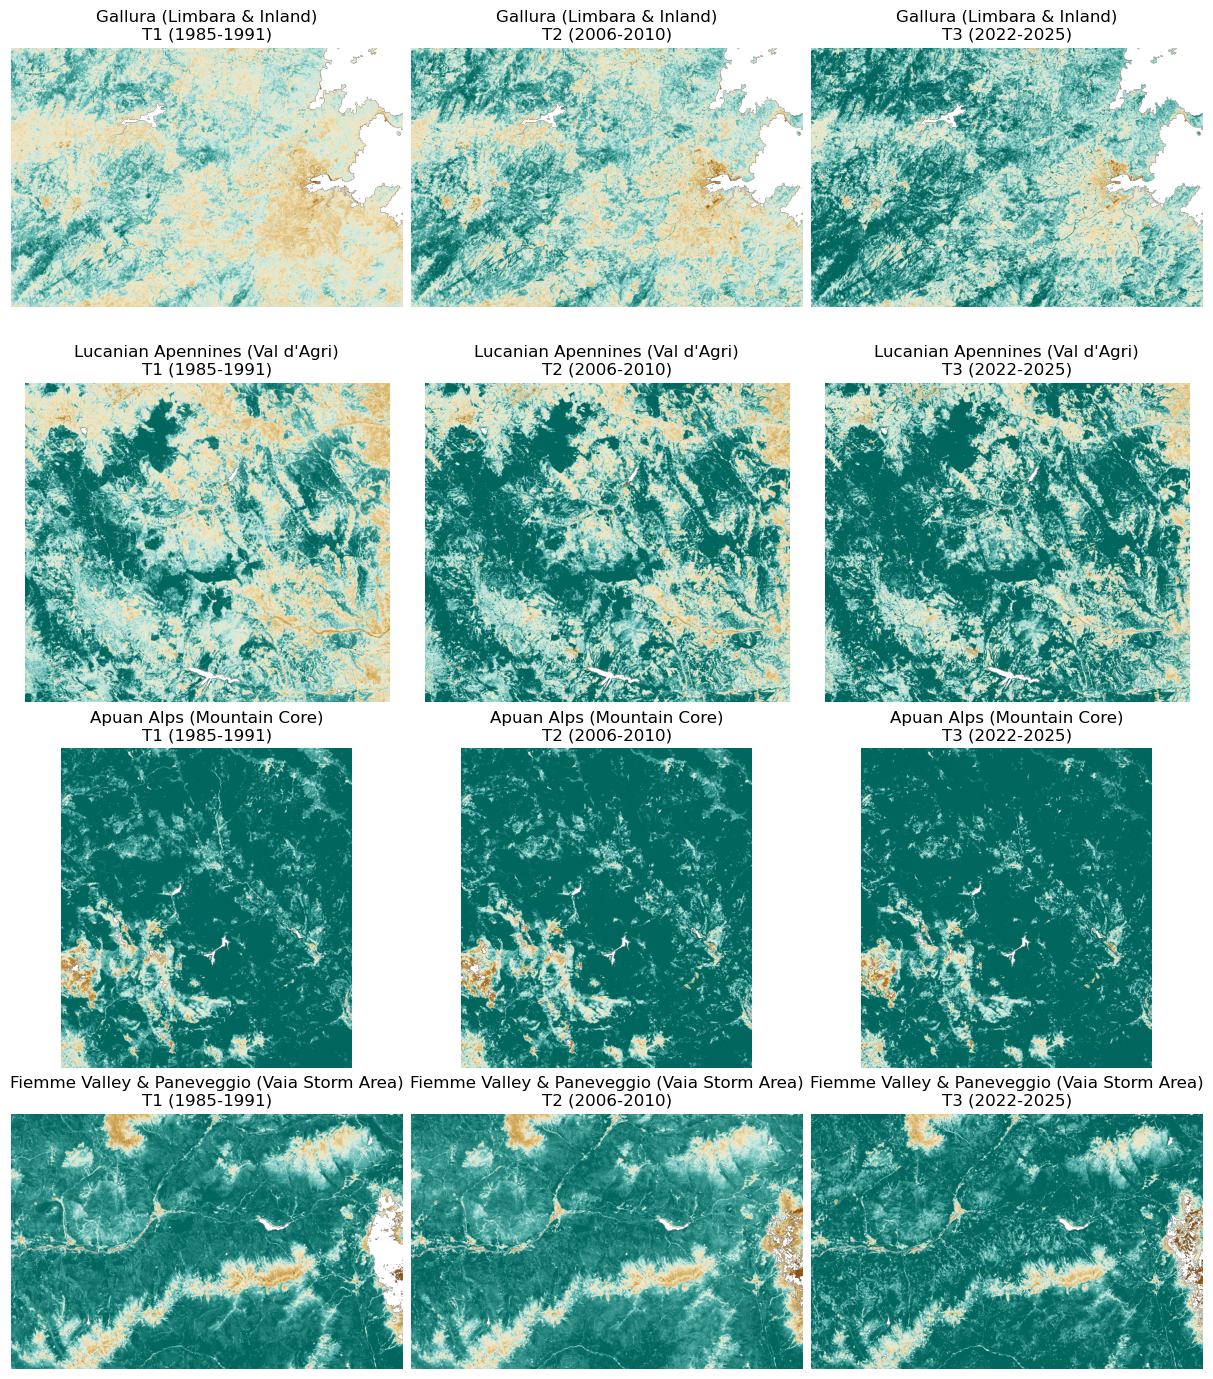

Saved results/ndvi_thumbnails/ndvi_comparison_grid.png


In [9]:
from math import ceil, cos, radians
from time import sleep
from urllib.error import URLError
from urllib.request import urlopen

NDVI_VIS_PARAMS = {
    "min": 0.0,
    "max": 0.8,
    "palette": ["8c510a", "d8b365", "f6e8c3", "c7eae5", "5ab4ac", "01665e"],
}
NDVI_THUMBNAIL_SCALE = 30
NDVI_THUMBNAIL_TIMEOUT_SECONDS = 300
NDVI_THUMBNAIL_RETRIES = 3
NDVI_THUMBNAIL_DIR = RESULTS_DIR / "ndvi_thumbnails"
NDVI_THUMBNAIL_DIR.mkdir(parents=True, exist_ok=True)
PNG_SIGNATURE = b"\x89PNG\r\n\x1a\n"


def thumbnail_dimensions(bbox, scale_m=NDVI_THUMBNAIL_SCALE):
    xmin, ymin, xmax, ymax = bbox
    center_latitude = (ymin + ymax) / 2
    metres_per_degree_lon = 111_320 * cos(radians(center_latitude))
    width = ceil((xmax - xmin) * metres_per_degree_lon / scale_m)
    height = ceil((ymax - ymin) * 111_320 / scale_m)
    return f"{width}x{height}"


def download_thumbnail(image, parameters, path):
    if path.is_file() and path.stat().st_size >= len(PNG_SIGNATURE):
        with path.open("rb") as existing_file:
            if existing_file.read(len(PNG_SIGNATURE)) == PNG_SIGNATURE:
                print(f"Using existing {path.relative_to(PROJECT_ROOT)}")
                return

    for attempt in range(1, NDVI_THUMBNAIL_RETRIES + 1):
        try:
            thumbnail_url = image.getThumbURL(parameters)
            with urlopen(thumbnail_url, timeout=NDVI_THUMBNAIL_TIMEOUT_SECONDS) as response:
                image_bytes = response.read()

            if not image_bytes.startswith(PNG_SIGNATURE):
                raise ValueError(f"Earth Engine returned an invalid PNG for {path.name}.")

            path.write_bytes(image_bytes)
            print(f"Saved {path.relative_to(PROJECT_ROOT)}")
            return
        except (TimeoutError, URLError) as error:
            is_timeout = isinstance(error, TimeoutError) or (
                isinstance(error, URLError) and isinstance(error.reason, TimeoutError)
            )
            if not is_timeout or attempt == NDVI_THUMBNAIL_RETRIES:
                raise
            wait_seconds = 5 * attempt
            print(
                f"Thumbnail timed out for {path.name}; "
                f"retrying in {wait_seconds}s ({attempt}/{NDVI_THUMBNAIL_RETRIES})."
            )
            sleep(wait_seconds)


ndvi_thumbnail_paths = {}
ndvi_thumbnail_images = {}
for region in AREA_KEYS:
    for period_key, period in config["periods"].items():
        aoi = areas[region]
        ndvi_image = (
            index_composite(aoi, period)
            .select("NDVI")
            .updateMask(land_mask())
            .clip(aoi)
        )
        path = NDVI_THUMBNAIL_DIR / f"{region}_{period_key}_NDVI.png"
        download_thumbnail(
            ndvi_image,
            {
                **NDVI_VIS_PARAMS,
                "region": aoi,
                "dimensions": thumbnail_dimensions(area_info[region]["bbox"]),
                "format": "png",
            },
            path,
        )

        ndvi_thumbnail_paths[(region, period_key)] = path
        ndvi_thumbnail_images[(region, period_key)] = plt.imread(path)

fig, axes = plt.subplots(len(AREA_KEYS), 3, figsize=(12, 14), constrained_layout=True)
for row, region in enumerate(AREA_KEYS):
    for column, period_key in enumerate(("T1", "T2", "T3")):
        axes[row, column].imshow(ndvi_thumbnail_images[(region, period_key)])
        axes[row, column].set_title(
            f"{area_info[region]['name']}\n{period_key} ({config['periods'][period_key]['start_year']}-"
            f"{config['periods'][period_key]['end_year']})"
        )
        axes[row, column].axis("off")

comparison_path = NDVI_THUMBNAIL_DIR / "ndvi_comparison_grid.png"
fig.savefig(comparison_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved {comparison_path.relative_to(PROJECT_ROOT)}")

## 8. Expanded forest origin and health

Compare expanded-forest pixels with CORINE 1990 land cover (nominal 1990; source coverage 1989–1998). Origin percentages use only expanded pixels covered by valid CORINE classes. T3 NDMI and NBR statistics are calculated inside the expanded-forest mask.

In [10]:
from src.qualitative_analysis import (
    calculate_expanded_forest_quality,
    render_t3_qualitative_figures,
)

t3_composites = {
    region: get_median_composite(areas[region], recent, config)
    for region in AREA_KEYS
}
qualitative_rows = calculate_expanded_forest_quality(
    areas=areas,
    deltas=deltas,
    t3_composites=t3_composites,
    area_info=area_info,
    land_mask=land_mask(),
    scale=STATS_SCALE,
)
qualitative_summary = pd.DataFrame(qualitative_rows).round(3)
qualitative_summary_path = RESULTS_DIR / "qualitative_summary_stats.csv"
qualitative_summary.to_csv(qualitative_summary_path, index=False)
print(f"Saved {qualitative_summary_path.relative_to(PROJECT_ROOT)}")

qualitative_figure_paths = render_t3_qualitative_figures(
    areas=areas,
    t3_composites=t3_composites,
    deltas=deltas,
    area_info=area_info,
    land_mask=land_mask(),
    output_dir=RESULTS_DIR / "qualitative_figures",
    max_side=MAP_LONG_SIDE_PX,
    nodata=NODATA,
)
for figure_path in qualitative_figure_paths:
    print(f"Saved {figure_path.relative_to(PROJECT_ROOT)}")

qualitative_summary

Saved results/qualitative_summary_stats.csv
Saved results/qualitative_figures/T3_NDVI_NBR_comparison_gallura.png
Saved results/qualitative_figures/T3_NDVI_NDMI_comparison_gallura.png
Saved results/qualitative_figures/T3_NDVI_NBR_comparison_basilicata.png
Saved results/qualitative_figures/T3_NDVI_NDMI_comparison_basilicata.png
Saved results/qualitative_figures/T3_NDVI_NBR_comparison_alpi_apuane.png
Saved results/qualitative_figures/T3_NDVI_NDMI_comparison_alpi_apuane.png
Saved results/qualitative_figures/T3_NDVI_NBR_comparison_trento.png
Saved results/qualitative_figures/T3_NDVI_NDMI_comparison_trento.png


,Region,Expanded Forest (km²),Mean T3 NDMI,Median T3 NDMI,Std T3 NDMI,Mean T3 NBR,Median T3 NBR,Std T3 NBR,CORINE mapped expansion (km²),CORINE agriculture (km²),CORINE agriculture (%),CORINE grassland (km²),CORINE grassland (%),CORINE shrubland (km²),CORINE shrubland (%),CORINE bare_ground (km²),CORINE bare_ground (%),CORINE other (km²),CORINE other (%)
0,Gallura (Limbara & Inland),530.718,0.220,0.209,0.085,0.502,0.490,0.093,534.998,138.020,25.798,4.163,0.778,256.785,47.997,14.534,2.717,121.497,22.710
1,Lucanian Apennines (Val d'Agri),547.785,0.236,0.232,0.073,0.517,0.514,0.085,557.720,201.166,36.069,54.549,9.781,78.678,14.107,1.919,0.344,221.409,39.699
2,Apuan Alps (Mountain Core),23.442,0.199,0.190,0.090,0.456,0.443,0.105,22.189,2.613,11.776,2.766,12.464,6.848,30.862,3.969,17.887,5.993,27.011
3,Fiemme Valley & Paneveggio (Vaia Storm Area),41.631,0.223,0.217,0.060,0.471,0.463,0.068,41.856,0.722,1.724,8.181,19.546,5.788,13.829,19.673,47.002,7.492,17.900
